Just added sharpening to previous code that predicted and grad cam was good but this performs poorly.

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import random
import matplotlib.pyplot as plt
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Define the device for computation
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Mount Google Drive to save and load the model (if using Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# Define the folder to save model checkpoints with date in the filename
date_str = datetime.now().strftime('%Y%m%d')
checkpoint_folder = f'/content/drive/My Drive/FYP/ModelCheckpointsHQ/Resnet/{date_str}/'
os.makedirs(checkpoint_folder, exist_ok=True)

# Data Augmentation for Training Set
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),  # VGG expects 224x224 input size
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Simple resizing for validation and test sets
transform_val_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

# Load datasets
data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
test_data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test'
train_dataset = datasets.ImageFolder(data_path, transform=transform_train)
test_dataset = datasets.ImageFolder(test_data_path, transform=transform_val_test)

# Split the dataset into 80% training and 20% validation
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

# Create data loaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Use Pre-trained VGG-16 model and modify it for binary classification
class VGG16Modified(nn.Module):
    def __init__(self):
        super(VGG16Modified, self).__init__()
        from torchvision.models import VGG16_Weights
        self.vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
        # Replace the classifier with a custom binary classification layer
        num_ftrs = self.vgg.classifier[6].in_features
        self.vgg.classifier[6] = nn.Sequential(
            nn.Dropout(0.5),  # Add dropout to the fully connected layer
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.vgg(x)

# Initialize the VGG model
model = VGG16Modified().to(device)

# Define loss function and optimizer with L2 regularization (weight decay)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.1, patience=3)

# Training loop with learning rate scheduler
def train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20):
    best_acc = 0.0
    train_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)  # Gradient clipping
            optimizer.step()

            running_loss += loss.item()

        # Print training loss
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {train_loss:.6f}")

        # Validate the model
        val_acc = validate(model, val_loader, criterion)
        val_accuracies.append(val_acc)
        scheduler.step(val_acc)

        # Save the best model
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_path = os.path.join(checkpoint_folder, f"best_model_{date_str}.pth")
            torch.save(model.state_dict(), best_model_path)
            print(f"New best model saved with accuracy: {best_acc:.2f}% at {best_model_path}")

    # Plot training and validation metrics
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Training Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Training Loss')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, label='Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy (%)')
    plt.title('Validation Accuracy')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Save the final model
    final_model_path = os.path.join(checkpoint_folder, f"final_model_{date_str}.pth")
    torch.save(model.state_dict(), final_model_path)
    print(f"Final model saved at {final_model_path}")

# Validation loop returning accuracy
def validate(model, loader, criterion):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Validation Accuracy: {accuracy:.2f}%')
    return accuracy

# Test function to evaluate on the test set
def test(model, loader, criterion):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f'Test Loss: {test_loss/len(loader):.6f}, Test Accuracy: {accuracy:.2f}%')

# Step 1: Train the model with learning rate scheduling
train(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs=20)

# Step 2: Evaluate the model on the test set
test(model, test_loader, criterion)


Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch [1/20], Loss: 0.400561
Validation Accuracy: 93.51%
New best model saved with accuracy: 93.51% at /content/drive/My Drive/FYP/ModelCheckpointsHQ/Resnet/20241207/best_model_20241207.pth
Epoch [2/20], Loss: 0.400153
Validation Accuracy: 90.91%
Epoch [3/20], Loss: 0.106256
Validation Accuracy: 90.26%
Epoch [4/20], Loss: 0.095172
Validation Accuracy: 96.75%
New best model saved with accuracy: 96.75% at /content/drive/My Drive/FYP/ModelCheckpointsHQ/Resnet/20241207/best_model_20241207.pth
Epoch [5/20], Loss: 0.081011
Validation Accuracy: 98.05%
New best model saved with accuracy: 98.05% at /content/drive/My Drive/FYP/ModelCheckpointsHQ/Resnet/20241207/best_model_20241207.pth
Epoch [6/20], Loss: 0.031059
Validation Accuracy: 98.05%
Epoch [7/20], Loss: 0.019269
Validation Accuracy: 97.40%


In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from PIL import Image
import os

# Mount Google Drive to save and load the model
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the saved model and the specific image
checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
image_path = '/content/download - 2024-08-02T115652.424.jpeg'  # Replace with the actual image file

# Define the transformation for the image (must match the test set transformations)
transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.ToTensor(),
])

# Load the saved model
class ResNet50Modified(nn.Module):
    def __init__(self):
        super(ResNet50Modified, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Replace the final fully connected layer to output 2 classes (Slaty-backed, Glaucous-winged)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Dropout(0.5),  # Add dropout to the fully connected layer
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.resnet(x)

# Initialize and load the saved model
model = ResNet50Modified()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu'), weights_only=True))

model.eval()

print(f"Model loaded from {checkpoint_path}")

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply the defined transformations
    image = image.unsqueeze(0)  # Add a batch dimension
    return image

# Retrieve class names directly from the training dataset directory
data_path = '/content/drive/My Drive/FYP/Dataset/Original_Adult_In-flight/train'
temp_dataset = datasets.ImageFolder(data_path)
class_names = list(temp_dataset.class_to_idx.keys())
print(f"Class names: {class_names}")

# Function to predict the class of the given image
def predict_image(model, image_tensor, class_names):
    """Predict the class of an image using the trained model."""
    with torch.no_grad():
        outputs = model(image_tensor)
        _, predicted = torch.max(outputs, 1)
        return class_names[predicted.item()]

# Preprocess the image
image_tensor = preprocess_image(image_path)

# Predict the class of the image
predicted_class = predict_image(model, image_tensor, class_names)
print(f"Predicted class: {predicted_class}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model loaded from /content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth
Class names: ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']


FileNotFoundError: [Errno 2] No such file or directory: '/content/download - 2024-08-02T115652.424.jpeg'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-15-d2354fc0baa4>:41: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))


Model loaded from /content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth
Class names: ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']


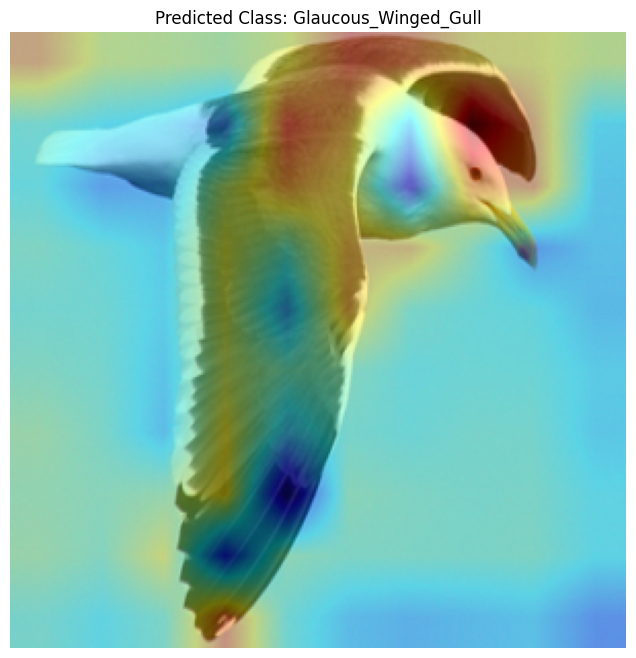

In [ ]:
import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import cv2
import os

# Mount Google Drive to save and load the model
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the saved model and the specific image
checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
image_path = '/content/007.jpg'

# Define the transformation for the image (must match the test set transformations)
transform = transforms.Compose([
    transforms.Resize((300, 300)),
    transforms.ToTensor(),
])

# Load the saved model
class ResNet50Modified(nn.Module):
    def __init__(self):
        super(ResNet50Modified, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Replace the final fully connected layer to output 2 classes (Slaty-backed, Glaucous-winged)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Dropout(0.5),  # Add dropout to the fully connected layer
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.resnet(x)

# Initialize and load the saved model
model = ResNet50Modified()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

print(f"Model loaded from {checkpoint_path}")

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply the defined transformations
    image = image.unsqueeze(0)  # Add a batch dimension
    return image

# Retrieve class names directly from the training dataset directory
data_path = '/content/drive/My Drive/FYP/Dataset/HQSBNGW/train'
temp_dataset = datasets.ImageFolder(data_path)
class_names = list(temp_dataset.class_to_idx.keys())
print(f"Class names: {class_names}")

# Function to generate Grad-CAM heatmap and show the predicted class
def generate_gradcam(model, image_tensor, target_layer, class_names):
    # Forward pass
    model.eval()
    features = []
    grads = []

    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()
    predicted_class = class_names[predicted_class_idx]

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Get gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of the gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))
    cam -= np.min(cam)
    cam /= np.max(cam)

    # Convert original image to show on heatmap
    original_image = image_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    original_image = original_image - np.min(original_image)
    original_image = original_image / np.max(original_image)

    # Create heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam_image = 0.4 * heatmap + 0.6 * original_image

    # Show the image with the predicted class name
    plt.figure(figsize=(8, 8))
    plt.title(f"Predicted Class: {predicted_class}")
    plt.imshow(cam_image)
    plt.axis('off')
    plt.show()

    # Remove hooks
    hook1.remove()
    hook2.remove()

# Use the final layer to see which parts of the image are activated
target_layer = model.resnet.layer4[-1]

# Preprocess the image
image_tensor = preprocess_image(image_path)

# Generate Grad-CAM for the specific image and show the predicted class
generate_gradcam(model, image_tensor, target_layer, class_names)


In [2]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Mount Google Drive to save and load the model
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the saved model and the test folder
checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test/Slaty_Backed_Gull'  # Path to the folder with images

# Define the transformation for the image (must match the test set transformations)
transform = transforms.Compose([
    transforms.Resize((300, 300)),  # Resize to match model input size
    transforms.ToTensor(),
])

# Load the saved model
class ResNet50Modified(nn.Module):
    def __init__(self):
        super(ResNet50Modified, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Replace the final fully connected layer to output 2 classes (Slaty-backed, Glaucous-winged)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Dropout(0.5),  # Add dropout to the fully connected layer
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.resnet(x)

# Initialize and load the saved model
model = ResNet50Modified()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

print(f"Model loaded from {checkpoint_path}")

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply the defined transformations
    image = image.unsqueeze(0)  # Add a batch dimension
    return image

# Retrieve class names directly from the training dataset directory
data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
temp_dataset = datasets.ImageFolder(data_path)
class_names = list(temp_dataset.class_to_idx.keys())
print(f"Class names: {class_names}")

# Function to generate Grad-CAM heatmap and show the predicted class
def generate_gradcam(model, image_tensor, target_layer, class_names):
    # Forward pass
    model.eval()
    features = []
    grads = []

    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()
    predicted_class = class_names[predicted_class_idx]

    # Debug: Print prediction
    print(f"Predicted class: {predicted_class}")

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Get gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of the gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))
    cam -= np.min(cam)
    cam /= np.max(cam)

    # Convert original image to show on heatmap
    original_image = image_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    original_image = original_image - np.min(original_image)
    original_image = original_image / np.max(original_image)

    # Create heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam_image = 0.4 * heatmap + 0.6 * original_image

    # Show the image with the predicted class name
    plt.figure(figsize=(8, 8))
    plt.title(f"Predicted Class: {predicted_class}")
    plt.imshow(cam_image)
    plt.axis('off')
    plt.show()

    # Remove hooks
    hook1.remove()
    hook2.remove()

# Use the final layer to see which parts of the image are activated
target_layer = model.resnet.layer4[-1]

# Loop over all images in the test folder
def generate_gradcam_for_all_images(test_folder_path, model, target_layer, class_names):
    image_files = os.listdir(test_folder_path)  # List all files in the test folder
    for image_file in image_files:
        image_path = os.path.join(test_folder_path, image_file)

        # Process only valid image formats (e.g., jpg, png)
        if image_path.lower().endswith(('.jpg', '.jpeg', '.png')):
            print(f"Processing image: {image_file}")  # Debugging step
            try:
                image_tensor = preprocess_image(image_path)
                generate_gradcam(model, image_tensor, target_layer, class_names)
            except Exception as e:
                print(f"Skipping image {image_file} due to error: {e}")

# Call the function to generate Grad-CAM for all images in the test folder
generate_gradcam_for_all_images(test_folder_path, model, target_layer, class_names)


Output hidden; open in https://colab.research.google.com to view.

In [5]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# # Define model path and dataset path
# checkpoint_path = '/content/drive/My Drive/FYP/ResNetHQ2/20241208/final_model.pth'
# test_folder_path = '/content/drive/My Drive/FYP/BOOK_IMAGES_GULL'  # Replace with your test folder path


checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test/Slaty_Backed_Gull'  # Path to the folder with images

# Load the Pretrained ResNet50 model
class PretrainedResNet50(nn.Module):
    def __init__(self):
        super(PretrainedResNet50, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Modify the final layer for binary classification (2 classes)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Linear(num_ftrs, 2)  # Binary classification
    def forward(self, x):
        return self.resnet(x)

# Load the trained ResNet model
model = PretrainedResNet50()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

# Define class names as per your dataset
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']  # Adjust based on your class order

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet expects 224x224 input size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply transformations
    image = image.unsqueeze(0)  # Add batch dimension
    return image

# Grad-CAM implementation
def generate_gradcam(model, image_tensor, target_layer):
    model.eval()
    features = []
    grads = []

    # Hook functions to capture features and gradients
    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks to the target layer
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Process gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))  # Resize to match image dimensions
    cam = (cam - np.min(cam)) / (np.max(cam) - np.min(cam))  # Normalize between 0 and 1
    cam = np.clip(cam, 0, 1)  # Make sure values are within [0, 1]
    return cam, predicted_class_idx


# Saliency Map implementation
def generate_saliency_map(model, image_tensor):
    image_tensor.requires_grad_()
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to calculate gradients
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Calculate saliency
    saliency = image_tensor.grad.data.abs()
    saliency, _ = torch.max(saliency, dim=1)  # Take max across channels
    saliency = saliency.squeeze().cpu().numpy()

    # Normalize for visualization
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    return saliency, predicted_class_idx

# Function to visualize results
def visualize_results(image_path, gradcam, saliency, predicted_class):
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image = np.array(original_image)

    # Grad-CAM heatmap overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * gradcam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    gradcam_image = np.clip(0.4 * heatmap + 0.6 * original_image, 0, 255).astype(np.uint8)

    # Plot images
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(original_image)
    plt.axis('off')

    # Grad-CAM
    plt.subplot(1, 3, 2)
    plt.title(f"Grad-CAM: {class_names[predicted_class]}")
    plt.imshow(gradcam_image)
    plt.axis('off')

    # Saliency Map
    plt.subplot(1, 3, 3)
    plt.title(f"Saliency Map: {class_names[predicted_class]}")
    plt.imshow(saliency, cmap='hot')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Process all images in the test folder
def process_test_folder(test_folder_path):
    target_layer = model.resnet.layer4[2].conv3  # Targeting a layer from ResNet for Grad-CAM (can be adjusted)
    for root, _, files in os.walk(test_folder_path):
        for file in files:
            image_path = os.path.join(root, file)
            print(f"Processing: {image_path}")

            # Preprocess the image
            image_tensor = preprocess_image(image_path)

            # Generate Grad-CAM and Saliency Map
            gradcam, predicted_class_idx_cam = generate_gradcam(model, image_tensor, target_layer)
            saliency, predicted_class_idx_sal = generate_saliency_map(model, image_tensor)

            # Ensure predictions from both methods match
            assert predicted_class_idx_cam == predicted_class_idx_sal, "Predicted class mismatch!"

            # Visualize results
            visualize_results(image_path, gradcam, saliency, predicted_class_idx_cam)

# Run the combined implementation on all images in the test folder
process_test_folder(test_folder_path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-5-461c561bdf44>:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))


RuntimeError: Error(s) in loading state_dict for PretrainedResNet50:
	Missing key(s) in state_dict: "resnet.fc.weight", "resnet.fc.bias". 
	Unexpected key(s) in state_dict: "resnet.fc.1.weight", "resnet.fc.1.bias". 

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-13-dca7a2efd496>:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_path, map_location=torch.device('cpu'))


Model loaded successfully from /content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth
Class names: ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']
Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/imageRTEs.jpg
Predicted class: Slaty_Backed_Gull


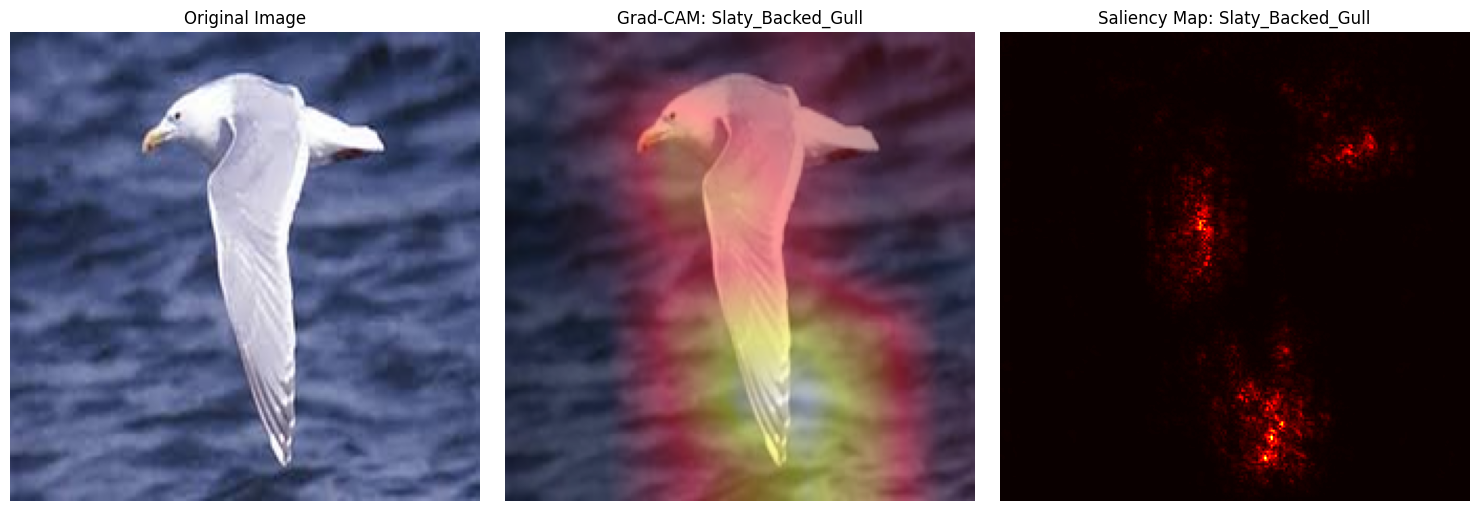

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/iDFGmages.jpg
Predicted class: Slaty_Backed_Gull


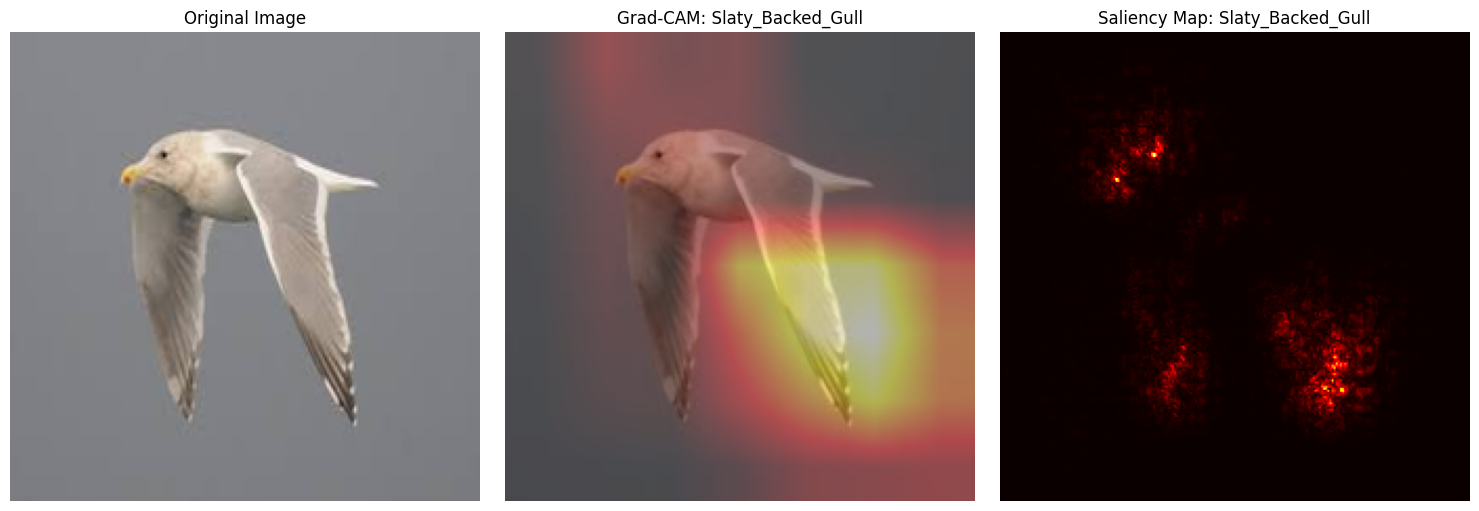

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/images.jpg
Predicted class: Slaty_Backed_Gull


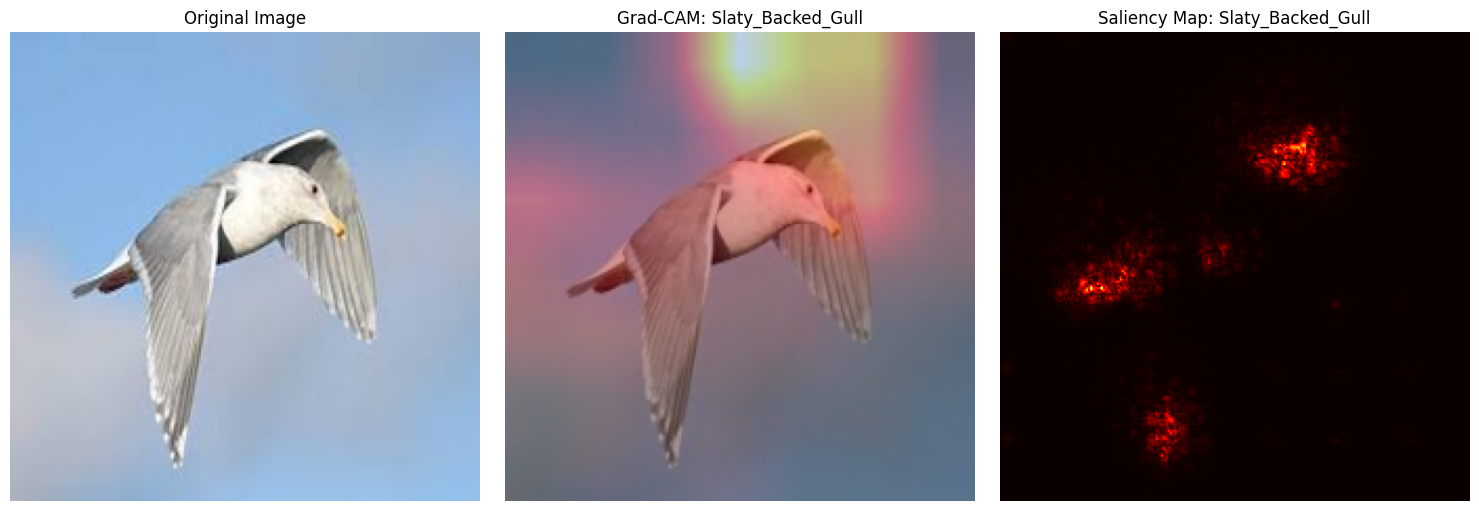

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/480 (11).jpeg
Predicted class: Slaty_Backed_Gull


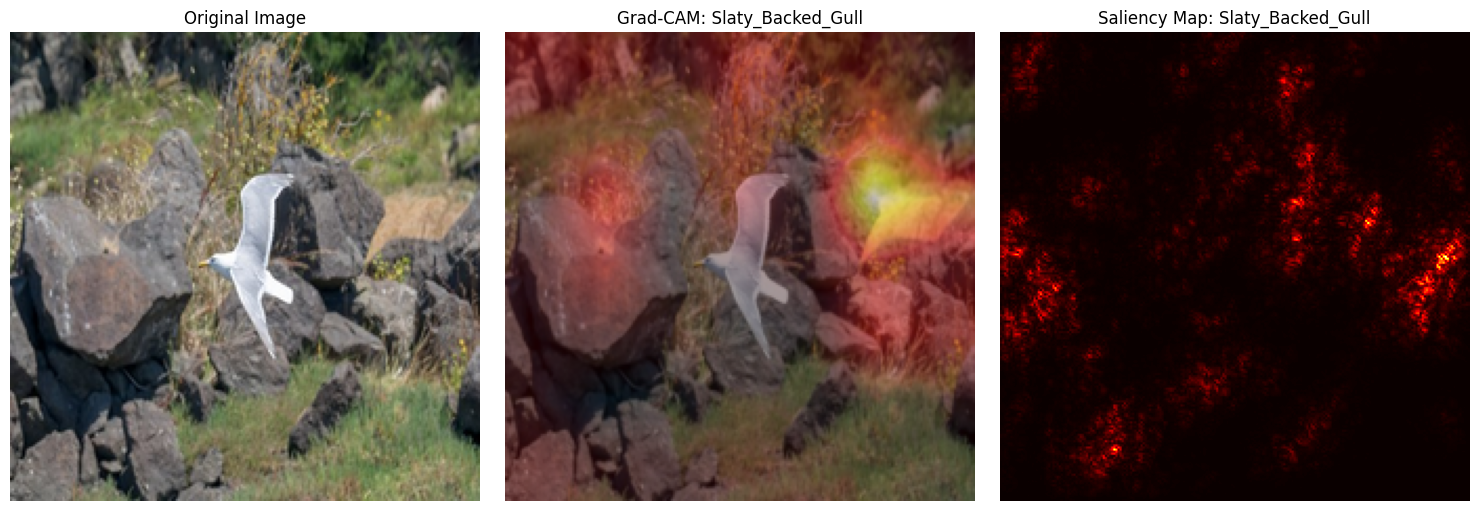

Processing: /content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull/320 (5).jpeg
Predicted class: Slaty_Backed_Gull


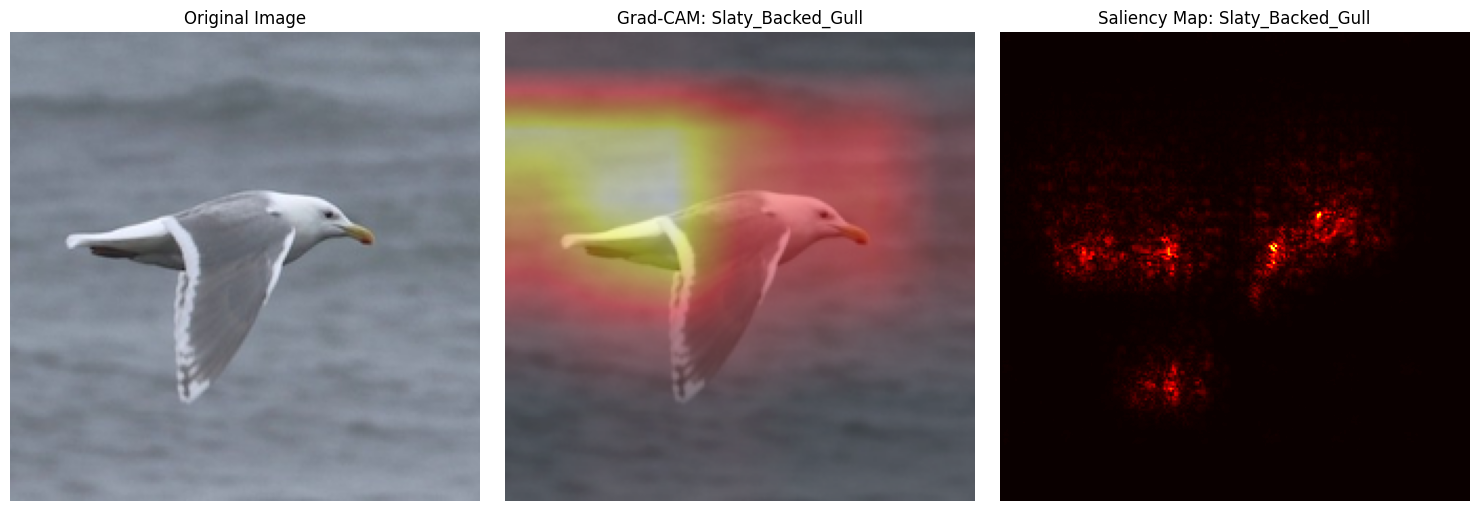

In [13]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the saved model and the test folder
checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test/Glaucous_Winged_Gull'  # Path to the folder with images

# Load the Pretrained ResNet50 model with matching architecture
class PretrainedResNet50(nn.Module):
    def __init__(self):
        super(PretrainedResNet50, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Modify the final fully connected layer to output 2 classes with Dropout
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Dropout(0.5),         # Add Dropout layer
            nn.Linear(num_ftrs, 2)   # Binary classification
        )

    def forward(self, x):
        return self.resnet(x)

# Initialize and load the saved model
model = PretrainedResNet50()
try:
    # Load the state_dict
    state_dict = torch.load(checkpoint_path, map_location=torch.device('cpu'))
    model.load_state_dict(state_dict, strict=False)  # Set strict=False to ignore missing keys like Dropout
    print(f"Model loaded successfully from {checkpoint_path}")
except RuntimeError as e:
    print(f"Error loading state_dict: {e}")
    # Optionally, inspect the state_dict keys
    # print(state_dict.keys())
    raise e

model.eval()

# Define class names as per your dataset
data_path = '/content/drive/My Drive/FYP/Dataset/HQ2/train'
temp_dataset = datasets.ImageFolder(data_path)
class_names = list(temp_dataset.class_to_idx.keys())
print(f"Class names: {class_names}")

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # ResNet expects 224x224 input size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply transformations
    image = image.unsqueeze(0)  # Add batch dimension
    return image

# Grad-CAM implementation
def generate_gradcam(model, image_tensor, target_layer):
    model.eval()
    features = []
    grads = []

    # Hook functions to capture features and gradients
    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks to the target layer
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()
    predicted_class = class_names[predicted_class_idx]

    # Debug: Print prediction
    print(f"Predicted class: {predicted_class}")

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Get gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]          # Shape: [C, H, W]
    feature_map = features[0].cpu().data.numpy()[0]   # Shape: [C, H, W]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))  # Resize to match image dimensions
    cam -= np.min(cam)
    cam /= (np.max(cam) + 1e-8)  # Normalize between 0 and 1, avoid division by zero

    # Convert original image to show on heatmap
    original_image = image_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    original_image = original_image * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])  # Unnormalize
    original_image = np.clip(original_image, 0, 1)  # Clip to [0,1]
    original_image = (original_image * 255).astype(np.uint8)  # Scale to [0,255]

    # Choose colormap based on predicted class
    if predicted_class_idx == 0:
        colormap = cv2.COLORMAP_COOL  # Blue hues
    elif predicted_class_idx == 1:
        colormap = cv2.COLORMAP_HOT   # Red hues
    else:
        colormap = cv2.COLORMAP_JET   # Default colormap

    # Create heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), colormap)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)  # Convert from BGR to RGB
    heatmap = np.float32(heatmap) / 255
    cam_image = 0.4 * heatmap + 0.6 * (original_image / 255.0)
    cam_image = np.clip(cam_image, 0, 1)  # Ensure values are within [0,1]
    cam_image = (cam_image * 255).astype(np.uint8)  # Scale back to [0,255]

    # Remove hooks
    hook1.remove()
    hook2.remove()

    return cam_image, predicted_class_idx

# Saliency Map implementation
def generate_saliency_map(model, image_tensor):
    image_tensor.requires_grad_()
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to calculate gradients
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Calculate saliency
    saliency = image_tensor.grad.data.abs()
    saliency, _ = torch.max(saliency, dim=1)  # Take max across channels
    saliency = saliency.squeeze().cpu().numpy()

    # Normalize for visualization
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min() + 1e-8)
    return saliency, predicted_class_idx

# Function to visualize results
def visualize_results(image_path, cam_image, saliency, predicted_class):
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image = np.array(original_image)

    # Plot images
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(original_image)
    plt.axis('off')

    # Grad-CAM
    plt.subplot(1, 3, 2)
    plt.title(f"Grad-CAM: {class_names[predicted_class]}")
    plt.imshow(cam_image)
    plt.axis('off')

    # Saliency Map
    plt.subplot(1, 3, 3)
    plt.title(f"Saliency Map: {class_names[predicted_class]}")
    plt.imshow(saliency, cmap='hot')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Process all images in the test folder
def process_test_folder(test_folder_path):
    target_layer = model.resnet.layer4[-1].conv3  # Targeting the last convolutional layer in ResNet50
    for root, _, files in os.walk(test_folder_path):
        for file in files:
            image_path = os.path.join(root, file)
            print(f"Processing: {image_path}")

            # Process only valid image formats (e.g., jpg, png)
            if image_path.lower().endswith(('.jpg', '.jpeg', '.png')):
                try:
                    # Preprocess the image
                    image_tensor = preprocess_image(image_path)

                    # Generate Grad-CAM
                    cam_image, predicted_class_idx_cam = generate_gradcam(model, image_tensor, target_layer)

                    # Generate Saliency Map
                    saliency, predicted_class_idx_sal = generate_saliency_map(model, image_tensor)

                    # Ensure predictions from both methods match
                    assert predicted_class_idx_cam == predicted_class_idx_sal, "Predicted class mismatch!"

                    # Visualize results
                    visualize_results(image_path, cam_image, saliency, predicted_class_idx_cam)
                except Exception as e:
                    print(f"Skipping image {file} due to error: {e}")

# Run the Grad-CAM and Saliency Map generation on all images in the test folder
process_test_folder(test_folder_path)


In [9]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models, datasets
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import cv2
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Mount Google Drive to save and load the model
from google.colab import drive
drive.mount('/content/drive')

# Define the path to the saved model and the test folder
checkpoint_path = '/content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth'
test_folder_path = '/content/drive/My Drive/FYP/Dataset/HQ2/test'  # Path to the folder with images

# Define the transformation for the image (must match the test set transformations)
transform = transforms.Compose([
    transforms.Resize((300, 300)),  # Resize to match model input size
    transforms.ToTensor(),
])

# Load the saved model
class ResNet50Modified(nn.Module):
    def __init__(self):
        super(ResNet50Modified, self).__init__()
        self.resnet = models.resnet50(pretrained=True)
        # Replace the final fully connected layer to output 2 classes (Slaty-backed, Glaucous-winged)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Sequential(
            nn.Dropout(0.5),  # Add dropout to the fully connected layer
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.resnet(x)

# Initialize and load the saved model
model = ResNet50Modified()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

print(f"Model loaded from {checkpoint_path}")

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply the defined transformations
    image = image.unsqueeze(0)  # Add a batch dimension
    return image

# Retrieve class names directly from the training dataset directory
data_path = '/content/drive/My Drive/FYP/Dataset/HQSBNGW/train'
temp_dataset = datasets.ImageFolder(data_path)
class_names = list(temp_dataset.class_to_idx.keys())
print(f"Class names: {class_names}")

# Function to generate Grad-CAM heatmap and show the predicted class
def generate_gradcam(model, image_tensor, target_layer, class_names):
    # Forward pass
    model.eval()
    features = []
    grads = []

    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()
    predicted_class = class_names[predicted_class_idx]

    # Debug: Print prediction
    print(f"Predicted class: {predicted_class}")

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Get gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of the gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))
    cam -= np.min(cam)
    cam /= np.max(cam)

    # Convert original image to show on heatmap
    original_image = image_tensor.squeeze().permute(1, 2, 0).cpu().numpy()
    original_image = original_image - np.min(original_image)
    original_image = original_image / np.max(original_image)

    # Create heatmap
    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = np.float32(heatmap) / 255
    cam_image = 0.4 * heatmap + 0.6 * original_image

    # Show the image with the predicted class name
    plt.figure(figsize=(8, 8))
    plt.title(f"Predicted Class: {predicted_class}")
    plt.imshow(cam_image)
    plt.axis('off')
    plt.show()

    # Remove hooks
    hook1.remove()
    hook2.remove()

# Use the final layer to see which parts of the image are activated
target_layer = model.resnet.layer4[-1]

# Loop over all images in the test folder and generate Grad-CAM
def generate_gradcam_for_all_images(test_folder_path, model, target_layer, class_names):
    true_labels = []
    predicted_labels = []

    # Loop over the subfolders (classes) in the test folder
    for class_folder in os.listdir(test_folder_path):
        class_folder_path = os.path.join(test_folder_path, class_folder)
        if os.path.isdir(class_folder_path):  # Only process directories
            for image_file in os.listdir(class_folder_path):
                image_path = os.path.join(class_folder_path, image_file)

                # Process only valid image formats (e.g., jpg, png)
                if image_path.lower().endswith(('.jpg', '.jpeg', '.png')):
                    try:
                        image_tensor = preprocess_image(image_path)
                        true_labels.append(class_folder)  # The true label is the folder name

                        # Generate Grad-CAM and make predictions
                        output = model(image_tensor)
                        predicted_class_idx = output.argmax().item()
                        predicted_class = class_names[predicted_class_idx]
                        predicted_labels.append(predicted_class)

                        # Generate Grad-CAM heatmap for the image
                        generate_gradcam(model, image_tensor, target_layer, class_names)

                    except Exception as e:
                        print(f"Skipping image {image_file} due to error: {e}")

    return true_labels, predicted_labels

# Generate Grad-CAM and collect true/predicted labels
true_labels, predicted_labels = generate_gradcam_for_all_images(test_folder_path, model, target_layer, class_names)

# Compute and plot confusion matrix
conf_matrix = confusion_matrix(true_labels, predicted_labels, labels=class_names)
print("Confusion Matrix:")
print(conf_matrix)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
<ipython-input-9-915928730029>:43: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more detail

Model loaded from /content/drive/My Drive/FYP/ModelCheckpointsHQ/best_model2310.pth


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/My Drive/FYP/Dataset/HQSBNGW/train'